# Neutrino response: native CLASS cb versus matched reconstruction

**Question:** why did the updated CLASS photometric neutrino forecasts stop matching the historical CAMB comparison?

Compare three nonlinear cold-dark-matter-plus-baryon (cb) spectra:

1. **CAMB reconstruction**: total nonlinear matter minus linear neutrino terms (reference).
2. **CLASS reconstruction**: the same approximation, using CLASS outputs.
3. **CLASS native cb**: CLASS's directly supplied nonlinear cb spectrum.

We plot the power, residuals and summed-neutrino-mass responses. The main comparison uses the same density factor **94.07**; a separate ablation uses **93.14** in CLASS. This is a comparison of conventions, not a claim that native CLASS cb is physically wrong.

**Cost:** saved-spectrum plotting is cheap. Set `RUN_SOLVERS = True` only to regenerate nine Boltzmann runs (several minutes, four OpenMP threads). No Fisher forecast or full validation suite is launched here.

Use the repository Python kernel. In a clean checkout: `uv sync --extra dev`, then open this notebook in that environment. A fresh checkout without cached data needs explicit solver regeneration.

## 1. Definitions and controlled settings

With $f_{cb}=\Omega_{cb}/\Omega_m$ and $f_\nu=\Omega_\nu/\Omega_m$, the reconstruction is

$$P_{cb}^{\rm rec}=\frac{P_{mm}^{\rm NL}-2f_{cb}f_\nu P_{cb,\nu}^{\rm L}-f_\nu^2P_{\nu,\nu}^{\rm L}}{f_{cb}^2}.$$

Each solver supplies its own total-matter and linear neutrino terms. Native CLASS cb uses `get_pk_cb_array(..., nonlinear=True)` instead. The CLASS reconstruction is explicitly formed from transfer functions by the diagnostic, independently of the backend's current default cb setting.

- Input **total-matter sigma8 = 0.81 is fixed**, not primordial As.
- Summed mass $M_\nu$ (`mnu`) = **0.054, 0.060, 0.066 eV**; other input cosmological parameters stay fixed.
- Four redshifts: **0.5, 1, 1.5, 2**.
- 60 physical wavenumbers: **0.001–10 Mpc$^{-1}$**; power is in **Mpc$^3$**.
- Both backends use the committed `nuvalidation_hp.yaml` profiles. Profiles/translation conventions are shown below. We do not force the internal nonlinear implementations to be identical.

The matched reference is the historically validated approximation, not an exact solution or a truth spectrum.

In [1]:
import json
import os
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Works when launched from the repository root or notebooks/.
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "scripts/validation/diagnose_neutrino_response.py").is_file())
RUN_SOLVERS = False
CACHE_DIR = Path(os.environ.get("CFP_NEUTRINO_DIAGNOSTIC",
    REPO / "scripts/benchmark_results/neutrino_isolation_20261012b"))
CONFIG = REPO / "scripts/validation/configs/common_specs_paper_LCDM_mnu_Neff.json"
SAVE_FIGURES = True
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.2})
print("Repository:", REPO)
print("Saved spectrum directory:", CACHE_DIR)

Repository: /home/santiago/CosmoProjects/cosmicfish_release/cfp-symbolic_overhaul
Saved spectrum directory: /home/santiago/CosmoProjects/cosmicfish_release/cfp-symbolic_overhaul/scripts/benchmark_results/neutrino_isolation_20261012b


In [2]:
if RUN_SOLVERS:
    # Never overwrite the archived control; each regeneration is a new directory.
    CACHE_DIR = REPO / "scripts/benchmark_results" / (
        "neutrino_notebook_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
    env = dict(os.environ, OMP_NUM_THREADS="4", OPENBLAS_NUM_THREADS="1",
               MKL_NUM_THREADS="1", PYTHONPATH=str(REPO))
    subprocess.run([sys.executable, "scripts/validation/diagnose_neutrino_response.py",
                    "--specs", str(CONFIG), "--outdir", str(CACHE_DIR)],
                   cwd=REPO, env=env, check=True)
required = [CACHE_DIR / name for name in ("spectra.npz", "provenance.json", "summary.json")]
if not all(p.is_file() for p in required):
    raise FileNotFoundError(
        "Saved spectra unavailable. Set RUN_SOLVERS=True to regenerate, or set "
        "CFP_NEUTRINO_DIAGNOSTIC to an existing diagnostic directory.")
with np.load(CACHE_DIR / "spectra.npz", allow_pickle=False) as archive:
    data = {name: archive[name].copy() for name in archive.files}
provenance = json.loads((CACHE_DIR / "provenance.json").read_text())
recorded_summary = json.loads((CACHE_DIR / "summary.json").read_text())
configured = json.loads(CONFIG.read_text())
# Older cache records point to the saved Fisher specs rather than embedding inputs.
if "fiducialpars" in provenance:
    actual = provenance["fiducialpars"]
elif Path(provenance["specs"]).is_file():
    actual = json.loads(Path(provenance["specs"]).read_text())["fiducialpars"]
else:
    actual = None
if actual is not None:
    assert actual == configured["fiducialpars"], "Cache uses different fiducial parameters"
    display(pd.Series(actual, name="Recorded input fiducial"))
else:
    print("Original input file unavailable: these are current configured inputs, not verified cache inputs.")
    display(pd.Series(configured["fiducialpars"], name="Current configuration"))
print("Recorded commit:", provenance["commit"])
print("Recorded versions:", provenance.get("versions", "Not stored in original cache"))
print("Input SHA256:", provenance["specs_sha256"])
print("Saved mass/redshift/wavenumber grids:", data["mnu"], data["z"], data["k"][[0, -1]])
FIG_DIR = CACHE_DIR / "figures"
if SAVE_FIGURES:
    FIG_DIR.mkdir(exist_ok=True)
def show_figure(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

Omegam    0.314571
Omegab    0.049199
h         0.673700
ns        0.966050
sigma8    0.810000
mnu       0.060000
Neff      3.044000
w0       -1.000000
wa        0.000000
Name: Recorded input fiducial, dtype: float64

Recorded commit: 74a3ca6a56ddf0b589cfa872ed8fa8d318efbdb2
Recorded versions: Not stored in original cache
Input SHA256: f8b15bf50e96a5ccbf0ef8ad06e9492ed5351a80e3524a067e49f8c8236f3c66
Saved mass/redshift/wavenumber grids: [0.054 0.06  0.066] [0.5 1.  1.5 2. ] [1.e-03 1.e+01]


### Solver settings and translation evidence

The input cosmology above is held fixed except for mass. CLASS's translated neutrino temperature/density settings are recorded per run. The primary plots deliberately select **94.07 for both solvers**, so the density-factor change is not conflated with the cb prescription.

In [3]:
import yaml
profile_rows = []
for backend in ("camb", "class"):
    profile_path = REPO / "cosmicfishpie/configs/default_boltzmann_yaml_files" / backend / "nuvalidation_hp.yaml"
    profile = yaml.safe_load(profile_path.read_text())
    profile_rows.append({"backend": backend, "current profile": profile_path.name,
                         "settings": json.dumps(profile, sort_keys=True)})
display(pd.DataFrame(profile_rows))
print("Profiles above are from the current checkout. Recorded profile hashes:",
      provenance.get("profile_sha256", "Not stored in original cache"))
rows = []
for run in provenance["runs"]:
    p = run["class_parameters"]
    if np.isclose(run["mnu"], 0.06):
        rows.append({"variant": run["tag"], **{key: p.get(key) for key in
            ("Omega_cdm", "Omega_ncdm", "m_ncdm", "T_ncdm", "N_ur", "non linear")}})
display(pd.DataFrame(rows))

,backend,current profile,settings
0,camb,nuvalidation_hp.yaml,"{""ACCURACY"": {""AccuracyBoost"": 3, ""accurate_ma..."
1,class,nuvalidation_hp.yaml,"{""ACCURACY"": {""background_Nloga"": 6000, ""hmcod..."


Profiles above are from the current checkout. Recorded profile hashes: Not stored in original cache


,variant,Omega_cdm,Omega_ncdm,m_ncdm,T_ncdm,N_ur,non linear
0,class_93.14,0.263937,0.001435,None,0.716369,2.029333,hmcode2020
1,class_94.07,0.263951,0.001421,None,0.716369,2.029333,hmcode2020


In [4]:
k, z, masses = data["k"], data["z"], data["mnu"]
assert np.all(np.diff(k) > 0) and np.all(np.diff(masses) > 0)
assert masses.size == 3 and np.isclose(masses[0] + masses[2], 2 * masses[1])
curves = {
    "CAMB reconstruction": data["camb_94.07_cb"],
    "CLASS reconstruction": data["class_94.07_cb_subtraction"],
    "CLASS native cb": data["class_94.07_cb"],
}
styles = {
    "CAMB reconstruction": {"color": "#222222", "linestyle": "-"},
    "CLASS reconstruction": {"color": "#2a7a3a", "linestyle": "--"},
    "CLASS native cb": {"color": "#23469b", "linestyle": ":"},
}
for name, powers in curves.items():
    assert powers.shape == (len(masses), len(z), len(k)), (name, powers.shape)
    assert np.isfinite(powers).all() and (powers > 0).all()
delta_mass = masses[2] - masses[0]
dP = {name: (p[2] - p[0]) / delta_mass for name, p in curves.items()}
dlogP = {name: (np.log(p[2]) - np.log(p[0])) / delta_mass
         for name, p in curves.items()}
reference = "CAMB reconstruction"
print("Finite-difference denominator:", delta_mass, "eV")

Finite-difference denominator: 0.012000000000000004 eV


## 2. Fiducial nonlinear cb power and residuals

Upper panels: $P_{cb}(k,z)$ at $M_\nu=0.060$ eV. Lower panels: $100(P/P_{\rm CAMB,rec}-1)$.
Nearly overlapping fiducial curves are expected; the percent residuals reveal the small differences. These are residuals to a chosen reference prescription, not absolute physical errors.

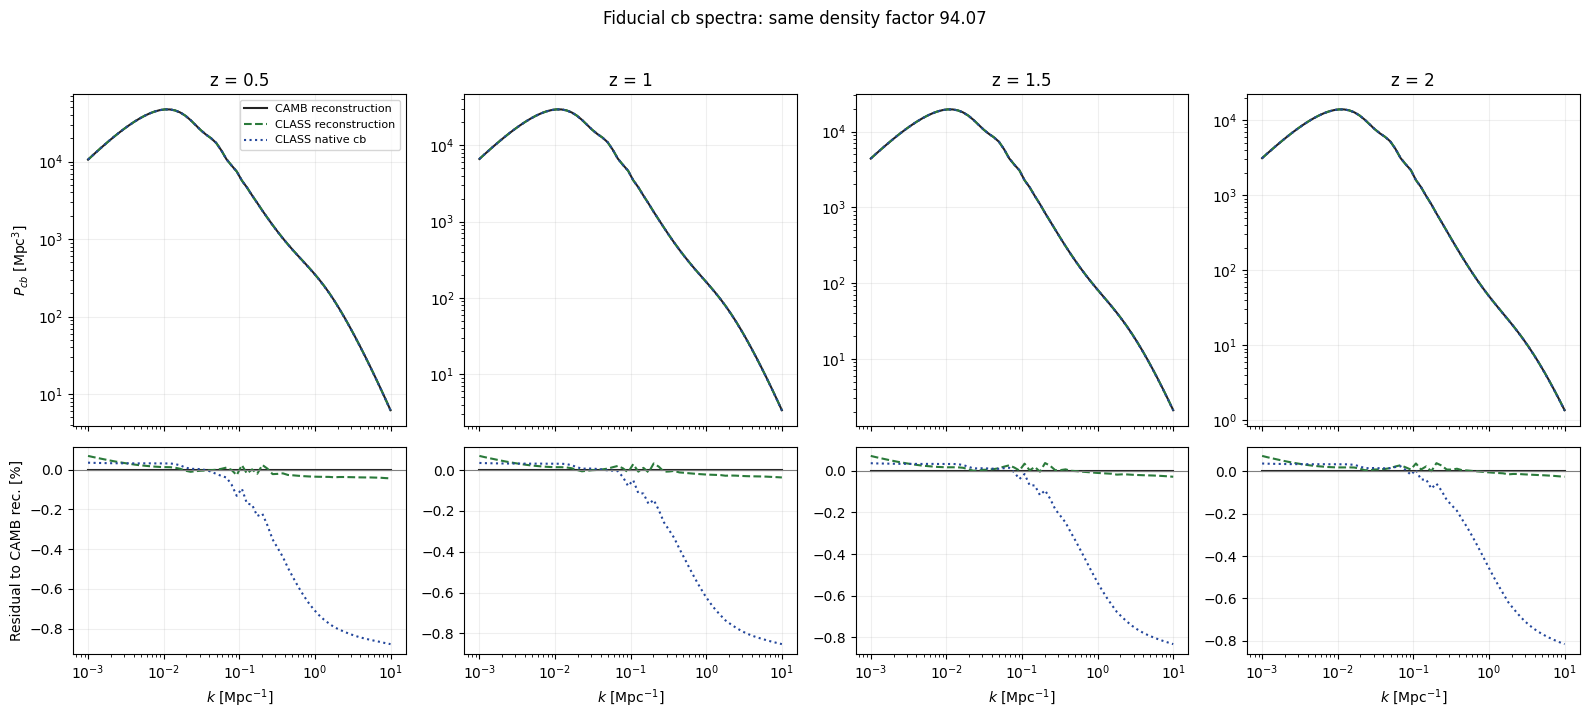

In [5]:
fig, axes = plt.subplots(2, len(z), figsize=(16, 7), sharex=True,
                         gridspec_kw={"height_ratios": [1.6, 1]})
for j, redshift in enumerate(z):
    for name, power in curves.items():
        axes[0, j].loglog(k, power[1, j], label=name, **styles[name])
        axes[1, j].semilogx(k, 100 * (power[1, j] / curves[reference][1, j] - 1), **styles[name])
    axes[0, j].set_title(f"z = {redshift:g}")
    axes[1, j].axhline(0, color="grey", lw=0.8)
    axes[1, j].set_xlabel(r"$k\ [\mathrm{Mpc}^{-1}]$")
axes[0, 0].set_ylabel(r"$P_{cb}\ [\mathrm{Mpc}^{3}]$")
axes[1, 0].set_ylabel("Residual to CAMB rec. [%]")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Fiducial cb spectra: same density factor 94.07", y=1.02)
show_figure(fig, "cb_power_and_residuals")

## 3. Derivatives with respect to summed neutrino mass

$$\left.\frac{\partial P}{\partial M_\nu}\right|_{\sigma_8}\simeq\frac{P(0.066)-P(0.054)}{0.012\,\mathrm{eV}},\qquad
\left.\frac{\partial\ln P}{\partial M_\nu}\right|_{\sigma_8}\simeq\frac{\ln P(0.066)-\ln P(0.054)}{0.012\,\mathrm{eV}}.$$

The direct derivative uses a symmetric-log vertical scale to retain its sign. The logarithmic derivative has units eV$^{-1}$. Fixed total sigma8 permits changes of sign across k; do not interpret these as fixed-As derivatives. These are two different finite-difference estimators, so dividing the direct derivative by the fiducial power need not exactly equal the log derivative at finite step.

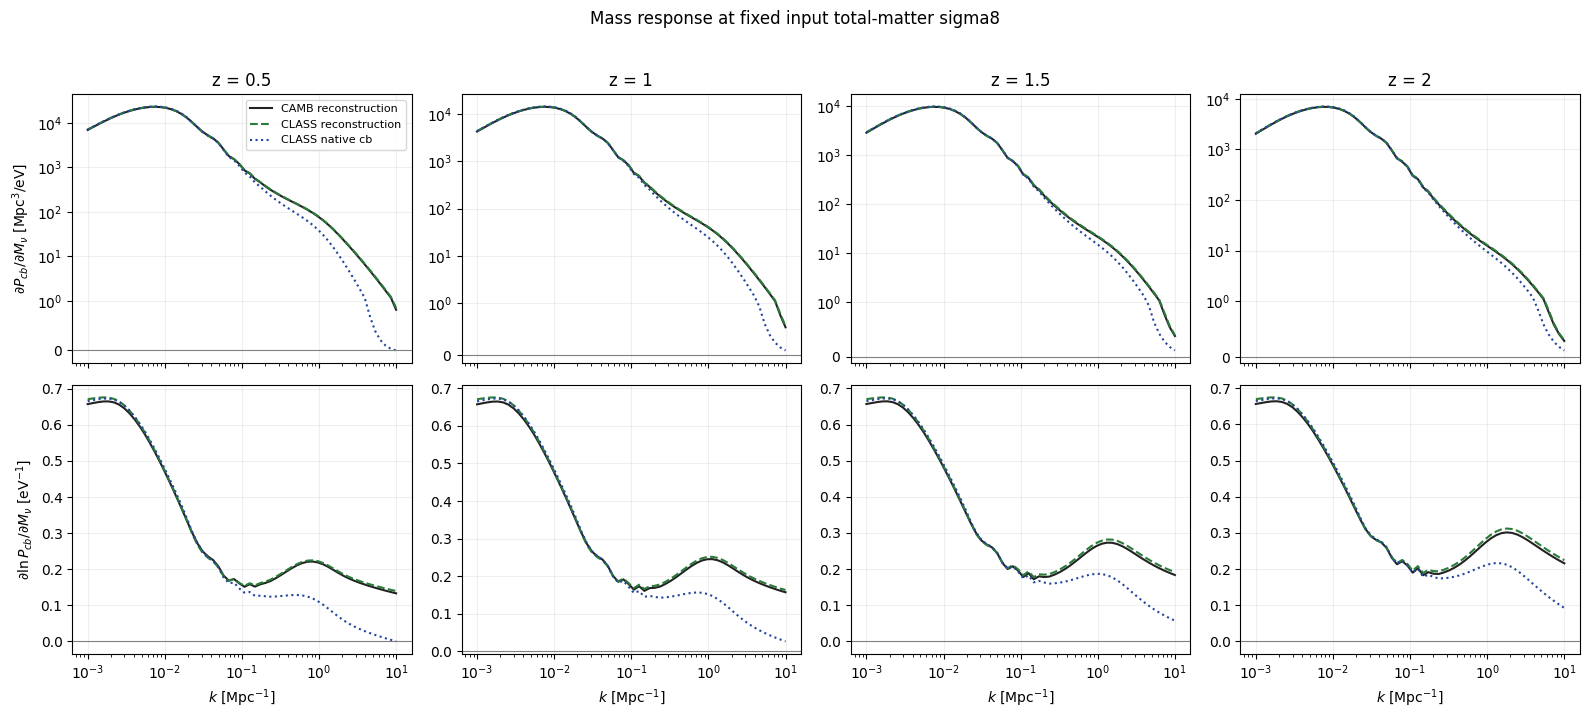

In [6]:
fig, axes = plt.subplots(2, len(z), figsize=(16, 7), sharex=True)
for j, redshift in enumerate(z):
    for name in curves:
        axes[0, j].semilogx(k, dP[name][j], label=name, **styles[name])
        axes[1, j].semilogx(k, dlogP[name][j], **styles[name])
    axes[0, j].set_yscale("symlog", linthresh=1)
    for ax in axes[:, j]:
        ax.axhline(0, color="grey", lw=0.8)
    axes[0, j].set_title(f"z = {redshift:g}")
    axes[1, j].set_xlabel(r"$k\ [\mathrm{Mpc}^{-1}]$")
axes[0, 0].set_ylabel(r"$\partial P_{cb}/\partial M_\nu\ [\mathrm{Mpc}^{3}/\mathrm{eV}]$")
axes[1, 0].set_ylabel(r"$\partial\ln P_{cb}/\partial M_\nu\ [\mathrm{eV}^{-1}]$")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Mass response at fixed input total-matter sigma8", y=1.02)
show_figure(fig, "cb_mass_derivatives")

## 4. Derivative differences: absolute first, relative with care

The top row shows $D-D_{\rm CAMB,rec}$, where $D=\partial\ln P/\partial M_\nu$.
The bottom row shows the signed relative difference $100(D/D_{\rm CAMB,rec}-1)$.
Relative values are masked where $|D_{\rm CAMB,rec}|<0.02$ eV$^{-1}$, to avoid dividing by a near-zero response. The absolute-difference plots remain unmasked. This visualization threshold is **not** a validation acceptance criterion; the summary table below retains the original unmasked diagnostic metrics.

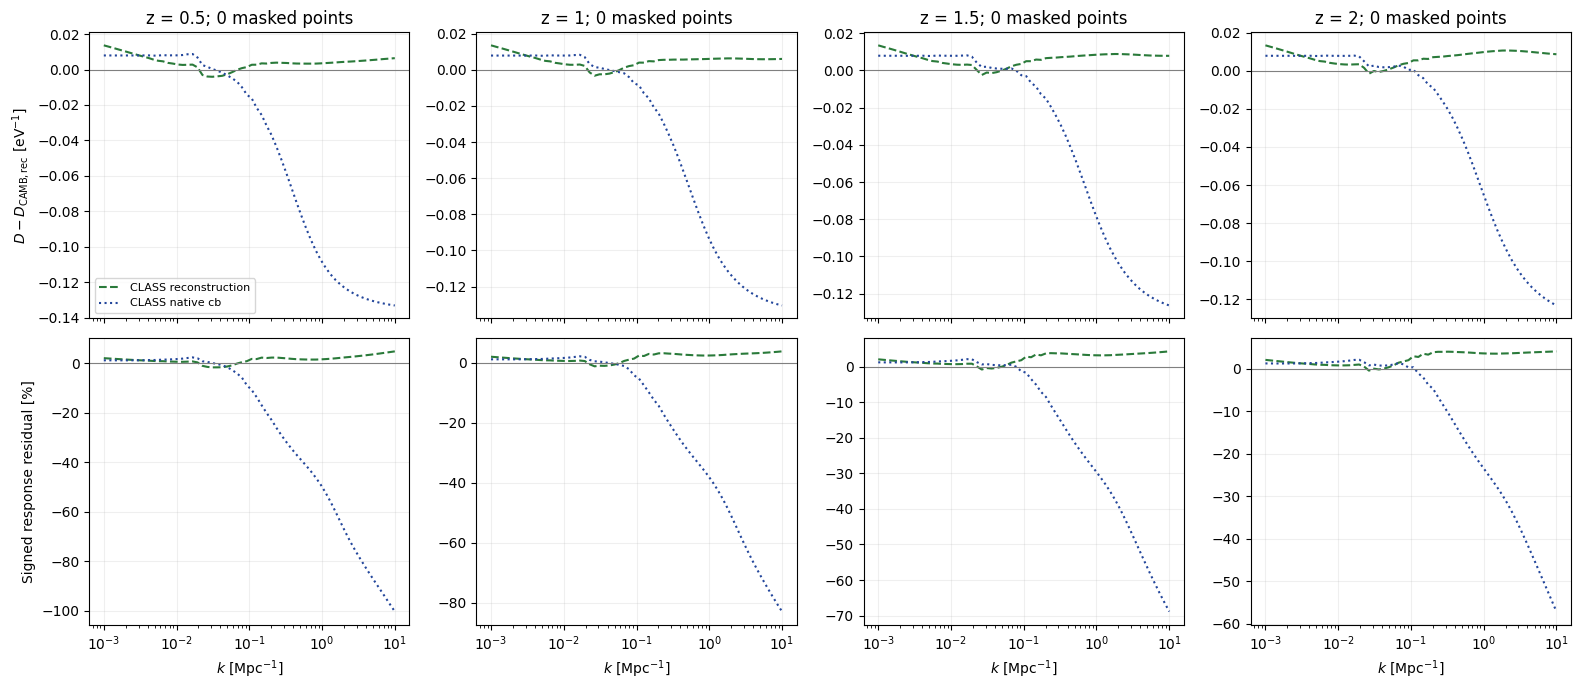

In [7]:
RESPONSE_FLOOR = 0.02  # eV^-1; visualization only
fig, axes = plt.subplots(2, len(z), figsize=(16, 7), sharex=True)
for j, redshift in enumerate(z):
    ref = dlogP[reference][j]
    valid = np.abs(ref) >= RESPONSE_FLOOR
    for name in curves:
        if name == reference:
            continue
        difference = dlogP[name][j] - ref
        relative = np.full_like(ref, np.nan)
        np.divide(100 * difference, ref, out=relative, where=valid)
        axes[0, j].semilogx(k, difference, label=name, **styles[name])
        axes[1, j].semilogx(k, relative, **styles[name])
    for ax in axes[:, j]:
        ax.axhline(0, color="grey", lw=0.8)
    axes[0, j].set_title(f"z = {redshift:g}; {np.count_nonzero(~valid)} masked points")
    axes[1, j].set_xlabel(r"$k\ [\mathrm{Mpc}^{-1}]$")
axes[0, 0].set_ylabel(r"$D-D_{\rm CAMB,rec}\ [\mathrm{eV}^{-1}]$")
axes[1, 0].set_ylabel("Signed response residual [%]")
axes[0, 0].legend(fontsize=8)
show_figure(fig, "cb_derivative_differences")

## 5. Separate density-factor ablation and quantitative checks

The following metrics average over this particular redshift/wavenumber sample, **not** over Fisher weights. Compare rows within a prescription to isolate the density factor; compare prescriptions at fixed factor to isolate the reconstruction choice. Large maximum relative differences should be read together with the absolute derivative differences.

In [8]:
rows = []
ref_power = curves[reference]
ref_response = dlogP[reference]
for factor in (93.14, 94.07):
    for prescription, suffix in (("native", "cb"), ("reconstruction", "cb_subtraction")):
        key = f"class_{factor}_{suffix}"
        p = data[key]
        response = (np.log(p[2]) - np.log(p[0])) / delta_mass
        difference = response - ref_response
        metrics = {
            "median_fiducial_difference_percent": float(np.median(abs(p[1] / ref_power[1] - 1)) * 100),
            "median_response_difference_percent": float(np.median(abs(difference / ref_response)) * 100),
            "max_response_difference_percent": float(np.max(abs(difference / ref_response)) * 100),
            "median_absolute_response_difference_per_eV": float(np.median(abs(difference))),
        }
        for metric, value in metrics.items():
            np.testing.assert_allclose(value, recorded_summary[key][metric], rtol=1e-8, atol=1e-10)
        rows.append({"CLASS prescription": prescription, "density factor": factor, **metrics})
summary = pd.DataFrame(rows)
display(summary.round(5))
band_rows = []
for low, high in ((0.001, 0.1), (0.1, 1), (1, 10)):
    mask = (k >= low) & (k <= high)
    for name in curves:
        if name == reference:
            continue
        band_rows.append({"prescription": name, "k interval [1/Mpc]": f"{low:g}–{high:g}",
                         "median absolute response difference [%]":
                         np.median(abs((dlogP[name][:, mask] - ref_response[:, mask]) /
                                       ref_response[:, mask])) * 100})
display(pd.DataFrame(band_rows).round(3))
print("All recomputed summary metrics agree with the saved diagnostic.")

,CLASS prescription,density factor,median_fiducial_difference_percent,median_response_difference_percent,max_response_difference_percent,median_absolute_response_difference_per_eV
0,native,93.14,0.07482,3.31424,100.69628,0.01503
1,reconstruction,93.14,0.02405,2.78695,5.52321,0.00806
2,native,94.07,0.03983,3.10270,100.35201,0.00819
3,reconstruction,94.07,0.01940,1.82190,4.82212,0.00574


,prescription,k interval [1/Mpc],median absolute response difference [%]
0,CLASS reconstruction,0.001–0.1,0.950
1,CLASS native cb,0.001–0.1,1.223
2,CLASS reconstruction,0.1–1,3.021
3,CLASS native cb,0.1–1,18.830
4,CLASS reconstruction,1–10,3.514
5,CLASS native cb,1–10,55.225


All recomputed summary metrics agree with the saved diagnostic.


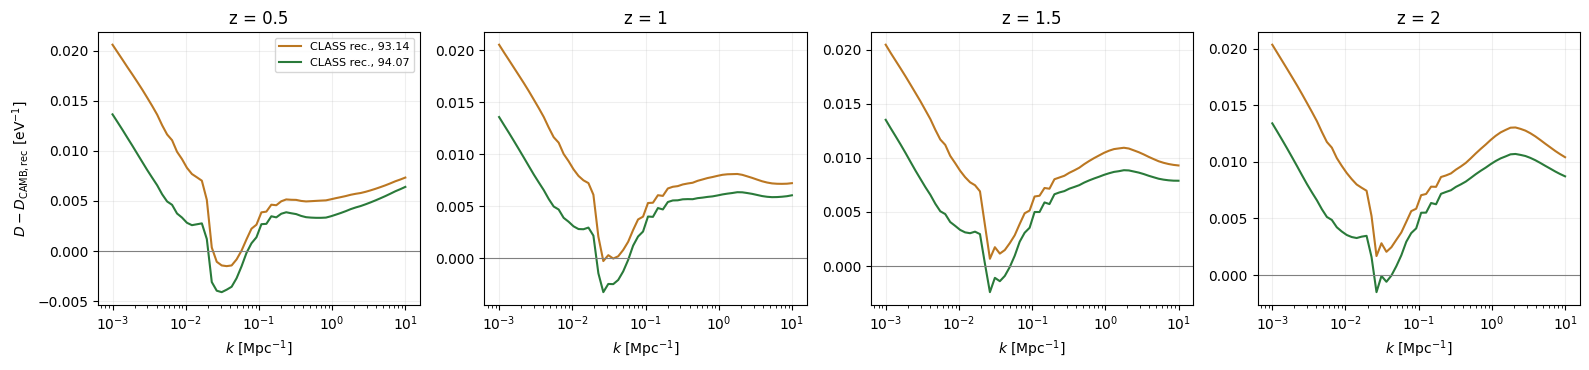

Figures saved to: /home/santiago/CosmoProjects/cosmicfish_release/cfp-symbolic_overhaul/scripts/benchmark_results/neutrino_isolation_20261012b/figures


In [9]:
fig, axes = plt.subplots(1, len(z), figsize=(16, 3.8), sharex=True)
for j, redshift in enumerate(z):
    for factor, color in ((93.14, "#bb7722"), (94.07, "#2a7a3a")):
        p = data[f"class_{factor}_cb_subtraction"]
        response = (np.log(p[2, j]) - np.log(p[0, j])) / delta_mass
        axes[j].semilogx(k, response - ref_response[j], color=color, label=f"CLASS rec., {factor}")
    axes[j].axhline(0, color="grey", lw=0.8)
    axes[j].set_title(f"z = {redshift:g}")
    axes[j].set_xlabel(r"$k\ [\mathrm{Mpc}^{-1}]$")
axes[0].set_ylabel(r"$D-D_{\rm CAMB,rec}\ [\mathrm{eV}^{-1}]$")
axes[0].legend(fontsize=8)
show_figure(fig, "cb_density_factor_control")
print("Figures saved to:", FIG_DIR if SAVE_FIGURES else "saving disabled")

## 6. Interpretation and Fisher confirmation

**Observed:** the native CLASS cb response differs substantially from the reconstruction on nonlinear scales, even when fiducial spectra look nearly identical. Restoring CLASS reconstruction with factor 94.07 reproduces the historical spectrum-response diagnostic (median **1.82190%**, maximum **4.82212%**).

**Independent saved Fisher check:** one corrected CLASS `03.2.0` run, compared with the archived CAMB matrix, reduced the maximum marginalized-error discrepancy **21.38% → 5.5266% (PASS)**. Sigma8 differed by **2.2720%** after correction. The new supported-grid checks remained enabled. This notebook does not rerun that Fisher or infer its results solely from the spectra.

**Scope:** the evidence explains recovery of the tested comparison. It does not select the physically best nonlinear cb model, demonstrate finite-difference step convergence, or establish recovery of every affected Fisher case. The three-way solver comparison includes their own nonlinear modelling and translation conventions; residuals are not all attributable to one numerical approximation in isolation.

**Next:** rerun the affected photo cases and the fixed-neutrino/Pmm controls on Frey using corrected code, then review and archive the reports. The deliberate Pmm teaching control is not expected to pass merely because cb reconstruction is restored.

See [`docs/source/neutrino_cb_regression.md`](../docs/source/neutrino_cb_regression.md) for the collaborator summary, configuration switch, evidence paths and follow-up command.